# AQUACAST AI: Forecasting Monthly Sales for a New Beverage Product
**Forecast Better. Produce Smarter. Distribute with Confidence.**

| | |
|---|---|
| **Student** | Atharva Soundankar |
| **Roll number** | AS25DXB020 |
| **Programme** | Master of Artificial Intelligence in Business (MAIB), September 2025 batch |
| **Institution** | SP Jain School of Global Management |
| **Subject** | AI in Operations |
| **Instructor** | Dr. Sandip Kumar Roy |
| **Assignment** | Session II, Lab Activity: Forecasting Monthly Sales for a New Beverage Product |

[Open in Colab](https://colab.research.google.com/github/mercydeez/atharva-soundankar-aquacast-ai-as25dxb020/blob/main/notebook/Atharva_Soundankar_AS25DXB020_Beverage_Forecasting.ipynb) · [GitHub repository](https://github.com/mercydeez/atharva-soundankar-aquacast-ai-as25dxb020)

## 1. Objective and business scenario
A beverage company has launched a new flavoured-water product in regional markets and wants to forecast demand for the coming months to plan production and distribution.

The new product has no long sales history of its own, so this notebook uses a **real, public proxy**: national US retail **unit sales of bottled water** (USDA Economic Research Service, Weekly Retail Food Sales, category *Beverages*, subcategory *Water*). The demand shape of the water category (trend, seasonality, shocks) is what a new flavoured water would launch into.

**Important:** these are category-level sales for all water products, not sales of the fictional product, and the source data ends in May 2023. Nothing here is presented as live 2026 sales.

The lecturer's seven tasks are covered in order: preprocessing with lag and seasonal features, model choice (Naive, ARIMA, Random Forest), a chronological train-test split, a forecast of the next 3 months, MAPE and WAPE, actual vs predicted plots, and interpretation. An LLM (Google Gemini) then writes an interpretation grounded in the computed results.

## 2. Setup
Runs in a fresh Google Colab runtime with **Runtime → Run all**. Only `google-genai` needs installing; the rest ships with Colab.

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "google-genai"], check=True)

import io, os, json, warnings, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
HORIZON = 3                     # forecast exactly the next three months
N_FOLDS = 4                     # rolling-origin folds of 3 months each (last 12 months)
GEMINI_MODEL = "gemini-3.5-flash-lite"
ERS_URL = "https://www.ers.usda.gov/media/6554/weekly-retail-food-sales-national-total-and-by-product-subcategory.csv"
ERS_PAGE = "https://www.ers.usda.gov/data-products/weekly-retail-food-sales"
FALLBACK_URL = "https://raw.githubusercontent.com/mercydeez/atharva-soundankar-aquacast-ai-as25dxb020/main/data/processed_monthly_sales.csv"
OUT = Path("aquacast_outputs"); OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
NAVY, TEAL, AMBER, RED, GREY = "#0f1f3d", "#0e8f8a", "#d98e04", "#c8402f", "#9aa5b5"
print("Colab:", IN_COLAB, "| pandas", pd.__version__)

Colab: False | pandas 2.3.3


## 3. Dataset download and loading
**Source:** USDA Economic Research Service, *Weekly Retail Food Sales*, national file (total and by product subcategory). Publisher: USDA ERS, built on Circana retail scanner data. The data product is discontinued; the files were last updated on 7 July 2023.

The notebook downloads the official CSV directly. If the USDA server cannot be reached, it falls back to the processed monthly file stored in this project's GitHub repository and says so.

In [2]:
DOWNLOAD_DATE = dt.date.today().isoformat()
raw = None
try:
    r = requests.get(ERS_URL, headers={"User-Agent": "Mozilla/5.0 (academic notebook; AQUACAST AI)"}, timeout=180)
    r.raise_for_status()
    raw = pd.read_csv(io.BytesIO(r.content), parse_dates=["Date"])
    DATA_MODE = "USDA ERS official download"
except Exception as e:
    DATA_MODE = "Fallback: processed monthly CSV from the project repository"
    print("USDA download failed:", e)
print("Data mode:", DATA_MODE, "| downloaded:", DOWNLOAD_DATE)
if raw is not None:
    print("Raw shape:", raw.shape)
    display(raw.head())

Data mode: USDA ERS official download | downloaded: 2026-11-12
Raw shape: (152280, 5)


,Date,Category,Subcategory,Variable,Value
0,2019-10-06,Alcohol,Other,Dollars,1.150829e+09
1,2019-10-06,All foods,All foods,Dollars,1.304327e+10
2,2019-10-06,Beverages,Carbonated non-alcoholic,Dollars,7.350713e+08
3,2019-10-06,Beverages,Fruit drinks and non-carbonated sugary,Dollars,7.290711e+08
4,2019-10-06,Beverages,Other,Dollars,2.271993e+08


## 4. Dataset preview and exploration
The file is in long format: one row per week, category, subcategory and variable.

In [3]:
if raw is not None:
    print("Weeks:", raw.Date.min().date(), "to", raw.Date.max().date(), "|", raw.Date.nunique(), "weekly dates")
    print("Categories:", sorted(raw.Category.unique()))
    print("Beverage subcategories:", sorted(raw.loc[raw.Category == "Beverages", "Subcategory"].unique()))
    print("Variables:", sorted(raw.Variable.unique()))

Weeks: 2019-10-06 to 2023-05-07 | 188 weekly dates
Categories: ['Alcohol', 'All foods', 'Beverages', 'Commercially prepared items', 'Dairy', 'Fats and oils', 'Fruits', 'Grains', 'Meats, eggs, and nuts', 'Other', 'Sugar and sweeteners', 'Vegetables']
Beverage subcategories: ['Carbonated non-alcoholic', 'Fruit drinks and non-carbonated sugary', 'Other', 'Water']
Variables: ['Dollars', 'Dollars 3 years ago', 'Dollars last year', 'Percent change dollars 1 year', 'Percent change dollars 3 years', 'Percent change share 1 year', 'Percent change share 3 years', 'Percent change units 1 year', 'Percent change units 3 years', 'Share', 'Share 3 years ago', 'Share last year', 'Unit sales', 'Unit sales 3 years ago', 'Unit sales last year']


## 5. Cleaning and validation
We keep **Beverages / Water** and pivot the variables into columns. We check for duplicates, missing values, non-positive values and gaps in the weekly calendar.

The file also publishes *Unit sales last year* and *Unit sales 3 years ago* for every week. We verify that these match the series' own values 52 weeks earlier. If they do, they legitimately extend the history back to October 2018, which gives about 4.5 years instead of 3.5 and makes seasonality much easier to estimate.

In [4]:
def build_weekly(wide, base, last_year, three_years):
    obs = {}
    for lag, col in [(0, base), (52, last_year), (156, three_years)]:
        for d, v in wide[col].dropna().items():
            obs.setdefault(d - pd.Timedelta(weeks=lag), []).append(float(v))
    series = pd.Series({k: np.mean(v) for k, v in obs.items()}).sort_index()
    spread = [(max(v) - min(v)) / np.mean(v) * 100 for v in obs.values() if len(v) > 1]
    return series, (max(spread) if spread else 0.0)

if raw is not None:
    water = raw[(raw.Category == "Beverages") & (raw.Subcategory == "Water")]
    dupes = int(water.duplicated(["Date", "Variable"]).sum())
    wide = water.pivot_table(index="Date", columns="Variable", values="Value", aggfunc="first").sort_index()
    print("Duplicate rows:", dupes, "| missing unit sales:", int(wide["Unit sales"].isna().sum()),
          "| non-positive unit sales:", int((wide["Unit sales"] <= 0).sum()))
    units_w, dis_u = build_weekly(wide, "Unit sales", "Unit sales last year", "Unit sales 3 years ago")
    dollars_w, dis_d = build_weekly(wide, "Dollars", "Dollars last year", "Dollars 3 years ago")
    weekly = pd.DataFrame({"units": units_w, "dollars": dollars_w})
    gaps = int((weekly.index.to_series().diff().dropna() != pd.Timedelta(days=7)).sum())
    LAST_WEEK = wide.index.max().date().isoformat()
    FIRST_WEEK = weekly.index.min().date().isoformat()
    print(f"Weekly history after extension: {FIRST_WEEK} to {LAST_WEEK} ({len(weekly)} weeks), calendar gaps: {gaps}")
    print(f"Max disagreement between overlapping published values: units {dis_u:.3f}%, dollars {dis_d:.3f}%")
    q1, q3 = np.percentile(weekly.units, [25, 75]); iqr = q3 - q1
    outliers = weekly[(weekly.units < q1 - 1.5 * iqr) | (weekly.units > q3 + 1.5 * iqr)]
    print("Weeks outside 1.5 IQR (kept, they are real demand events):", [d.date().isoformat() for d in outliers.index])
    assert gaps == 0 and dupes == 0 and dis_u < 0.1

Duplicate rows: 0 | missing unit sales: 0 | non-positive unit sales: 0
Weekly history after extension: 2018-10-07 to 2023-05-07 (240 weeks), calendar gaps: 0
Max disagreement between overlapping published values: units 0.022%, dollars 0.020%
Weeks outside 1.5 IQR (kept, they are real demand events): ['2020-03-15']


## 6. Monthly aggregation
Weeks end on Sunday, and a week ending on date D covers D-6 to D. Weeks that cross a month boundary are **split by days**: each day gets one seventh of the week's sales, and the days are summed by calendar month. This assumes sales are spread evenly within a week.

A month is kept only if all its days are covered. That drops partial boundary months, which would otherwise look like false collapses in demand. Here that is May 2023, because the data ends on 7 May. The history starts with the week ending 7 October 2018, which covers 1 to 7 October, so October 2018 is complete.

In [5]:
def weekly_to_monthly(weekly):
    days = []
    for end, row in weekly.iterrows():
        for k in range(7):
            days.append((end - pd.Timedelta(days=6 - k), row.units / 7, row.dollars / 7))
    daily = pd.DataFrame(days, columns=["day", "units", "dollars"]).set_index("day")
    g = daily.groupby(daily.index.to_period("M"))
    m = pd.DataFrame({"units": g["units"].sum(), "dollars": g["dollars"].sum(min_count=1),
                      "dollars_complete": g["dollars"].apply(lambda s: s.notna().all()),
                      "covered_days": g.size()})
    m["days_in_month"] = [p.days_in_month for p in m.index]
    m.loc[~m.dollars_complete, "dollars"] = np.nan
    full, partial = m[m.covered_days == m.days_in_month], m[m.covered_days != m.days_in_month]
    return full, partial

if raw is not None:
    full, partial = weekly_to_monthly(weekly)
    monthly = pd.DataFrame({"month": full.index.to_timestamp(), "units": full.units.round(0),
                            "dollars": full.dollars.round(0)})
    monthly["avg_price"] = (monthly.dollars / monthly.units).round(4)
    DROPPED = [str(p) for p in partial.index]
else:
    monthly = pd.read_csv(FALLBACK_URL, parse_dates=["month"])
    FIRST_WEEK, LAST_WEEK, DROPPED = "2018-10-07", "2023-05-07", ["2018-09", "2023-05"]
monthly = monthly.reset_index(drop=True)
y = pd.Series(monthly.units.values, index=pd.DatetimeIndex(monthly.month, freq="MS"), name="units")
print("Dropped partial months:", DROPPED)
print(f"Monthly series: {y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m}, {len(y)} months")
monthly.to_csv(OUT / "processed_monthly_sales.csv", index=False)
display(monthly.tail(6))

Dropped partial months: ['2023-05']
Monthly series: 2018-10 to 2023-04, 55 months


,month,units,dollars,avg_price
49,2022-11-01,608385558.0,1.793428e+09,2.9478
50,2022-12-01,619056251.0,1.841092e+09,2.9740
51,2023-01-01,621856114.0,1.858160e+09,2.9881
52,2023-02-01,581780816.0,1.746798e+09,3.0025
53,2023-03-01,668826041.0,2.007357e+09,3.0013
54,2023-04-01,692158886.0,2.080636e+09,3.0060


### Exploratory view: level, trend and seasonality

Trend strength 0.29, seasonal strength 0.91 (0 = none, 1 = dominant)
Peak month Jul (123.4% of average), trough Feb (83.7%)
Full calendar-year totals (millions of units): {2019: 8505.0, 2020: 8552.0, 2021: 9067.0, 2022: 8693.0} | YoY %: {2020: 0.5, 2021: 6.0, 2022: -4.1}


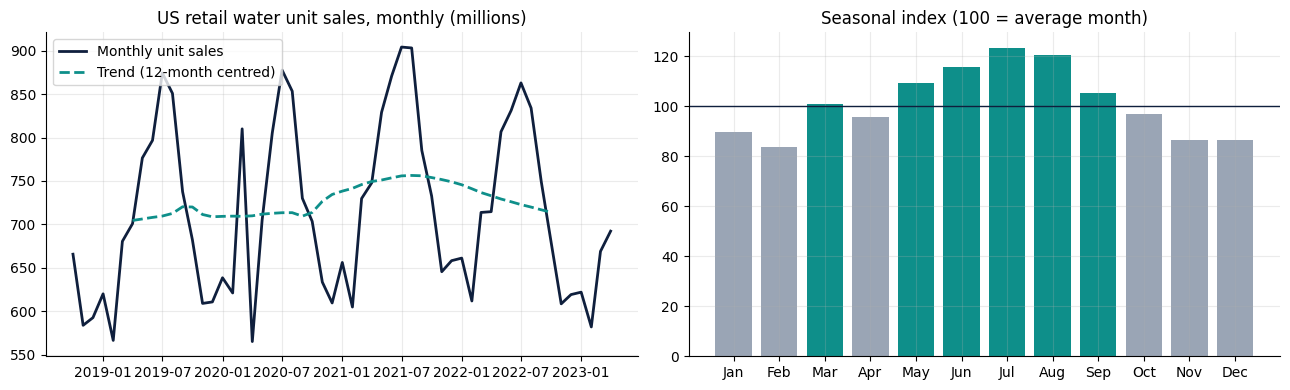

In [6]:
dec = seasonal_decompose(y, model="additive", period=12)
resid = dec.resid.dropna()
trend_strength = max(0.0, 1 - resid.var() / (dec.trend.dropna().loc[resid.index] + resid).var())
seasonal_strength = max(0.0, 1 - resid.var() / (dec.seasonal.loc[resid.index] + resid).var())
season_idx = (y.groupby(y.index.month).mean() / y.mean() * 100).round(1)
annual = y.groupby(y.index.year).agg(["sum", "count"])
full_years = annual[annual["count"] == 12]["sum"]
yoy = (full_years.pct_change() * 100).round(1)
PEAK, TROUGH = int(season_idx.idxmax()), int(season_idx.idxmin())
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
print(f"Trend strength {trend_strength:.2f}, seasonal strength {seasonal_strength:.2f} (0 = none, 1 = dominant)")
print(f"Peak month {MONTHS[PEAK-1]} ({season_idx.max()}% of average), trough {MONTHS[TROUGH-1]} ({season_idx.min()}%)")
print("Full calendar-year totals (millions of units):", (full_years / 1e6).round(0).to_dict(), "| YoY %:", yoy.dropna().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(y.index, y / 1e6, color=NAVY, lw=2, label="Monthly unit sales")
ax[0].plot(dec.trend.index, dec.trend / 1e6, color=TEAL, lw=2, ls="--", label="Trend (12-month centred)")
ax[0].set_title("US retail water unit sales, monthly (millions)"); ax[0].legend()
ax[1].bar(MONTHS, season_idx.values, color=[TEAL if v >= 100 else GREY for v in season_idx.values])
ax[1].axhline(100, color=NAVY, lw=1); ax[1].set_title("Seasonal index (100 = average month)")
plt.tight_layout(); plt.show()

## 7. Feature engineering
These features are used by the Random Forest. Every feature uses **only past values**: lags are shifted and the rolling mean is computed on the shifted series, so there is no target leakage.
- `lag1`, `lag2`, `lag3`: the last three months
- `lag12`: the same month last year, for seasonality
- `roll3`: the mean of the previous three months
- `m_sin`, `m_cos`: the calendar month on a circle
- `t`: a trend index

In [7]:
def make_features(s):
    f = pd.DataFrame({"y": s.values}, index=s.index)
    for L in (1, 2, 3, 12):
        f[f"lag{L}"] = s.shift(L).values
    f["roll3"] = s.shift(1).rolling(3).mean().values
    f["m_sin"] = np.sin(2 * np.pi * s.index.month / 12)
    f["m_cos"] = np.cos(2 * np.pi * s.index.month / 12)
    f["t"] = np.arange(len(s))
    return f

FEATURES = ["lag1", "lag2", "lag3", "lag12", "roll3", "m_sin", "m_cos", "t"]
display(make_features(y).dropna().head(3))

,y,lag1,lag2,lag3,lag12,roll3,m_sin,m_cos,t
month,,,,,,,,,
2019-10-01,682083397.0,737573431.0,850882825.0,874371723.0,665589001.0,8.209427e+08,-8.660254e-01,0.500000,12
2019-11-01,608879209.0,682083397.0,737573431.0,850882825.0,583657417.0,7.568466e+08,-5.000000e-01,0.866025,13
2019-12-01,610596220.0,608879209.0,682083397.0,737573431.0,592471752.0,6.761787e+08,-2.449294e-16,1.000000,14


## 8. Models
| Model | Idea | Why it is here |
|---|---|---|
| **Naive** | Next months = last observed month | Mandatory baseline |
| **Seasonal Naive** | Next month = same month last year | Baseline that knows seasonality |
| **SARIMA** | ARIMA with a 12-month seasonal part, order chosen by AIC on training data only | Classical time-series model (the ARIMA option) |
| **Random Forest** | 500 trees on the lag, seasonal and trend features, forecasting 3 steps recursively | ML option |

XGBoost is optional on the slide. With 55 monthly points it adds a tuning burden without a clear benefit over the Random Forest, so it is left out.

In [8]:
def fc_naive(train, h):
    return np.repeat(train.iloc[-1], h), None

def fc_snaive(train, h):
    return np.array([train.iloc[len(train) - 12 + i] for i in range(h)]), None

SARIMA_GRID = [((p, d, q), (P, D, Q, 12)) for (p, d, q) in [(0, 1, 1), (1, 1, 0), (1, 1, 1), (1, 0, 0)]
               for (P, D, Q) in [(0, 0, 0), (0, 1, 1), (1, 0, 0)]]

def fc_sarima(train, h, return_model=False):
    best = None
    for order, sorder in SARIMA_GRID:
        try:
            m = SARIMAX(train, order=order, seasonal_order=sorder, trend="n",
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            if np.isfinite(m.aic) and (best is None or m.aic < best[0].aic):
                best = (m, order, sorder)
        except Exception:
            pass
    m, order, sorder = best
    f = m.get_forecast(h)
    info = {"order": order, "seasonal_order": sorder, "aic": float(m.aic),
            "ci80": f.conf_int(alpha=0.2).values, "ci95": f.conf_int(alpha=0.05).values}
    return f.predicted_mean.values, info

def fc_rf(train, h):
    f = make_features(train).dropna()
    model = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
    model.fit(f[FEATURES], f["y"])
    s = train.copy()
    preds = []
    for _ in range(h):                       # recursive multi-step forecast
        nxt = s.index[-1] + pd.offsets.MonthBegin(1)
        s = pd.concat([s, pd.Series([np.nan], index=[nxt])])
        row = make_features(s).iloc[[-1]][FEATURES]
        p = float(model.predict(row)[0]); preds.append(p); s.iloc[-1] = p
    imp = dict(zip(FEATURES, np.round(model.feature_importances_, 3)))
    return np.array(preds), {"importance": imp}

MODELS = {"naive": ("Naive", fc_naive), "snaive": ("Seasonal Naive", fc_snaive),
          "sarima": ("SARIMA", fc_sarima), "rf": ("Random Forest", fc_rf)}

## 9. Chronological train-test split and rolling-origin validation
The data is **never shuffled**. The headline test is a **3-month holdout**: train on everything up to January 2023, then predict February to April 2023.

A single 3-month window is noisy, so we also use **rolling-origin validation** with 4 consecutive 3-month windows covering the last 12 months. For each window, the model is refitted on all data before it and asked to predict the next 3 months. Model selection uses the pooled result.

In [9]:
def mape(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    mask = a != 0
    return (float(np.mean(np.abs((a[mask] - p[mask]) / a[mask])) * 100) if mask.any() else float("nan")), int((~mask).sum())

def wape(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    denom = np.abs(a).sum()
    return float(np.abs(a - p).sum() / denom * 100) if denom > 0 else float("nan")

n = len(y)
origins = [n - HORIZON * k for k in range(N_FOLDS, 0, -1)]   # last fold = 3-month holdout
results = {}
for key, (name, fn) in MODELS.items():
    folds = []
    for o in origins:
        train, test = y.iloc[:o], y.iloc[o:o + HORIZON]
        pred, info = fn(train, HORIZON)
        m_, zeros = mape(test.values, pred)
        folds.append({"train_end": f"{train.index[-1]:%Y-%m}", "test_months": [f"{d:%Y-%m}" for d in test.index],
                      "actual": test.values.tolist(), "pred": np.round(pred, 0).tolist(),
                      "mape": m_, "wape": wape(test.values, pred), "zero_actuals": zeros})
    A = np.concatenate([f["actual"] for f in folds]); P = np.concatenate([f["pred"] for f in folds])
    results[key] = {"key": key, "name": name, "cv_mape": mape(A, P)[0], "cv_wape": wape(A, P),
                    "holdout_mape": folds[-1]["mape"], "holdout_wape": folds[-1]["wape"], "folds": folds}

table = pd.DataFrame([{"Model": r["name"], "Holdout MAPE %": r["holdout_mape"], "Holdout WAPE %": r["holdout_wape"],
                       "Rolling-origin MAPE %": r["cv_mape"], "Rolling-origin WAPE %": r["cv_wape"]}
                      for r in results.values()]).round(2).sort_values("Rolling-origin WAPE %")
display(table)
BEST = min(results, key=lambda k: results[k]["cv_wape"])
print("Holdout window:", results[BEST]["folds"][-1]["test_months"], "| train ends", results[BEST]["folds"][-1]["train_end"])
print("Best model by rolling-origin WAPE:", results[BEST]["name"])

,Model,Holdout MAPE %,Holdout WAPE %,Rolling-origin MAPE %,Rolling-origin WAPE %
2,SARIMA,2.65,2.75,2.29,2.34
3,Random Forest,8.04,8.00,5.50,5.21
1,Seasonal Naive,5.03,5.01,5.58,5.54
0,Naive,8.02,8.10,11.93,12.04


Holdout window: ['2023-02', '2023-03', '2023-04'] | train ends 2023-01
Best model by rolling-origin WAPE: SARIMA


### Manual check of the metric formulas
This recomputes MAPE and WAPE for the Naive holdout by hand, to show the functions are correct.

In [10]:
f = results["naive"]["folds"][-1]
a, p = np.array(f["actual"]), np.array(f["pred"])
hand_mape = sum(abs(ai - pi) / ai for ai, pi in zip(a, p)) / len(a) * 100
hand_wape = sum(abs(ai - pi) for ai, pi in zip(a, p)) / sum(a) * 100
print(f"MAPE by hand {hand_mape:.4f} vs function {f['mape']:.4f} | WAPE by hand {hand_wape:.4f} vs function {f['wape']:.4f}")
assert abs(hand_mape - f["mape"]) < 1e-9 and abs(hand_wape - f["wape"]) < 1e-9

MAPE by hand 8.0227 vs function 8.0227 | WAPE by hand 8.0992 vs function 8.0992


## 10. Actual vs predicted sales
Each panel shows the last 24 months of actual sales and each model's predictions in the four test windows. The holdout window is the last one.

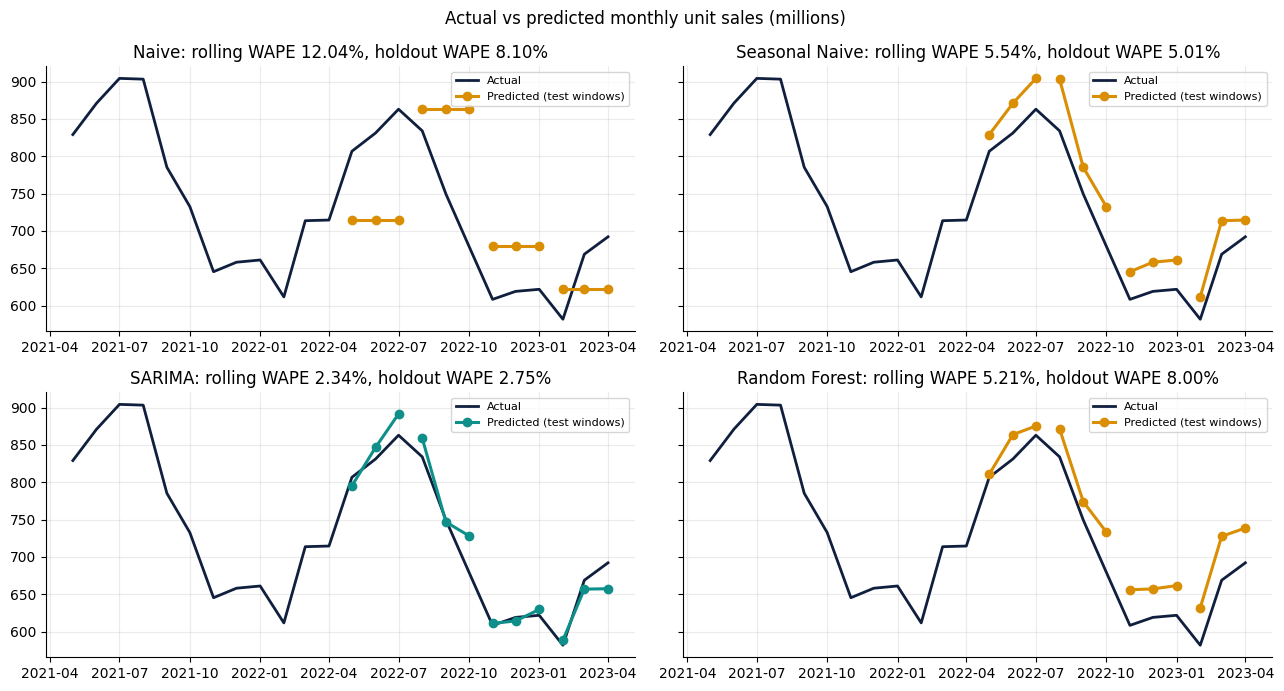

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True)
recent = y.iloc[-24:]
for ax, (key, r) in zip(axes.ravel(), results.items()):
    ax.plot(recent.index, recent / 1e6, color=NAVY, lw=2, label="Actual")
    for i, fo in enumerate(r["folds"]):
        idx = pd.to_datetime(fo["test_months"])
        ax.plot(idx, np.array(fo["pred"]) / 1e6, color=TEAL if key == BEST else AMBER, lw=2.2, marker="o",
                label="Predicted (test windows)" if i == 0 else None)
    ax.set_title(f"{r['name']}: rolling WAPE {r['cv_wape']:.2f}%, holdout WAPE {r['holdout_wape']:.2f}%")
    ax.legend(fontsize=8)
fig.suptitle("Actual vs predicted monthly unit sales (millions)"); plt.tight_layout(); plt.show()

## 11. Forecast for the next three months
The selected model is refitted on **all 55 months**, then it forecasts exactly the three months after the last full month (May, June and July 2023).

**Prediction intervals:**
- SARIMA gives its own model-based 80% and 95% intervals.
- For the other models, the intervals come from their rolling-origin errors at the same forecast step: point ± z × RMSE at that step.

We also store every model's forecast so the dashboard can compare them.

Selected model: SARIMA | SARIMA(1, 1, 0)x(1, 0, 0, 12) model-based intervals


,Month,Forecast (units),80% low,80% high,95% low,95% high
0,2023-05,747837303.0,650169186.0,845505419.0,598466808.0,8.972078e+08
1,2023-06,766526449.0,647320748.0,885732150.0,584217062.0,9.488358e+08
2,2023-07,787503834.0,645511291.0,929496377.0,570344979.0,1.004663e+09


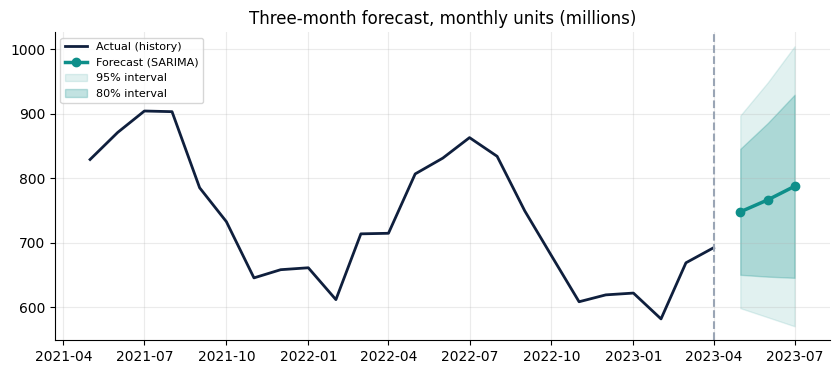

In [12]:
cv_rmse_by_step = {}
for key, r in results.items():
    errs = np.array([np.array(fo["actual"]) - np.array(fo["pred"]) for fo in r["folds"]])   # folds x steps
    cv_rmse_by_step[key] = np.sqrt((errs ** 2).mean(axis=0))

future_idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=HORIZON, freq="MS")
all_fc = {}
for key, (name, fn) in MODELS.items():
    pred, info = fn(y, HORIZON)
    if key == "sarima":
        lo80, hi80 = info["ci80"][:, 0], info["ci80"][:, 1]; lo95, hi95 = info["ci95"][:, 0], info["ci95"][:, 1]
        method = f"SARIMA{info['order']}x{info['seasonal_order']} model-based intervals"
        results[key]["params"] = {"order": list(info["order"]), "seasonal_order": list(info["seasonal_order"]), "aic": round(info["aic"], 1)}
    else:
        rm = cv_rmse_by_step[key]
        lo80, hi80, lo95, hi95 = pred - 1.2816 * rm, pred + 1.2816 * rm, pred - 1.96 * rm, pred + 1.96 * rm
        method = "Point ± z × rolling-origin RMSE at each forecast step"
        if key == "rf":
            results[key]["params"] = {"n_estimators": 500, "min_samples_leaf": 2, "features": FEATURES, "importance": info["importance"]}
    all_fc[key] = {"model": key, "name": name, "months": [f"{d:%Y-%m}" for d in future_idx],
                   "point": np.round(pred, 0).tolist(), "lo80": np.round(lo80, 0).tolist(), "hi80": np.round(hi80, 0).tolist(),
                   "lo95": np.round(lo95, 0).tolist(), "hi95": np.round(hi95, 0).tolist(), "interval_method": method}

FC = all_fc[BEST]
fc_table = pd.DataFrame({"Month": FC["months"], "Forecast (units)": FC["point"], "80% low": FC["lo80"], "80% high": FC["hi80"],
                         "95% low": FC["lo95"], "95% high": FC["hi95"]})
assert len(fc_table) == 3 and FC["months"][0] == f"{(y.index[-1] + pd.offsets.MonthBegin(1)):%Y-%m}"
print("Selected model:", results[BEST]["name"], "|", FC["interval_method"])
display(fc_table)

fig, ax = plt.subplots()
hist = y.iloc[-24:]
ax.plot(hist.index, hist / 1e6, color=NAVY, lw=2, label="Actual (history)")
ax.plot(future_idx, np.array(FC["point"]) / 1e6, color=TEAL, lw=2.5, marker="o", label=f"Forecast ({results[BEST]['name']})")
ax.fill_between(future_idx, np.array(FC["lo95"]) / 1e6, np.array(FC["hi95"]) / 1e6, color=TEAL, alpha=.12, label="95% interval")
ax.fill_between(future_idx, np.array(FC["lo80"]) / 1e6, np.array(FC["hi80"]) / 1e6, color=TEAL, alpha=.25, label="80% interval")
ax.axvline(y.index[-1], color=GREY, ls="--"); ax.set_title("Three-month forecast, monthly units (millions)"); ax.legend(fontsize=8)
plt.show()

## 12. Interpretation: answers to the lecturer's questions
These answers are computed from the results above rather than written by hand. The numbers in the text update if the data changes.

In [13]:
best, naive = results[BEST], results["naive"]
ranked = sorted(results.values(), key=lambda r: r["cv_wape"])
last12, prev12 = y.iloc[-12:].sum(), y.iloc[-24:-12].sum()
growth12 = (last12 / prev12 - 1) * 100
fc_total = sum(FC["point"]); same_months_ly = sum(y.loc[[d - pd.DateOffset(years=1) for d in future_idx]].values)
fc_vs_ly = (fc_total / same_months_ly - 1) * 100
buffer = sum(h - p for h, p in zip(FC["hi80"], FC["point"]))

q1 = (f"Seasonality is clear: seasonal strength {seasonal_strength:.2f} on a 0 to 1 scale. Demand peaks in {MONTHS[PEAK-1]} "
      f"({season_idx.max():.0f}% of an average month) and bottoms out in {MONTHS[TROUGH-1]} ({season_idx.min():.0f}%). "
      f"Trend strength is {trend_strength:.2f}; the last 12 months are {growth12:+.1f}% versus the 12 before. "
      f"The seasonal models capture this pattern, while Naive cannot, because it simply carries the last month forward.")
q2 = (f"{best['name']} performed best, with rolling-origin WAPE {best['cv_wape']:.2f}% and MAPE {best['cv_mape']:.2f}% over 12 test months "
      f"(3-month holdout WAPE {best['holdout_wape']:.2f}%), against {naive['cv_wape']:.2f}% for the Naive baseline. "
      f"Ranking by WAPE: " + ", ".join(f"{r['name']} {r['cv_wape']:.2f}%" for r in ranked) + ". "
      f"It wins because it models the 12-month seasonal cycle and the level of recent months together.")
q3 = [f"Plan production for {FC['months'][0]} to {FC['months'][-1]} at about {fc_total/1e6:,.0f} million category units in total "
      f"({fc_vs_ly:+.1f}% versus the same months last year), and scale that to the new product's expected share.",
      f"Hold an extra buffer of about {buffer/1e6:,.0f} million units across the three months (the gap to the 80% upper bound) "
      f"to protect service in the peak season.",
      f"Front-load distribution before {MONTHS[PEAK-1]}, the peak month, and plan promotions or capacity for the "
      f"{MONTHS[TROUGH-1]} trough.",
      "Re-run the forecast monthly as new sell-through data for the flavoured water arrives, and switch from the category "
      "proxy to the product's own history once about 12 months exist."]
print("1. How well did the model capture seasonality or trends?\n  ", q1)
print("\n2. Which model performed best and why?\n  ", q2)
print("\n3. What recommendations would you give the company?")
for i, s in enumerate(q3, 1): print(f"   {i}. {s}")

1. How well did the model capture seasonality or trends?
   Seasonality is clear: seasonal strength 0.91 on a 0 to 1 scale. Demand peaks in Jul (123% of an average month) and bottoms out in Feb (84%). Trend strength is 0.29; the last 12 months are -5.2% versus the 12 before. The seasonal models capture this pattern, while Naive cannot, because it simply carries the last month forward.

2. Which model performed best and why?
   SARIMA performed best, with rolling-origin WAPE 2.34% and MAPE 2.29% over 12 test months (3-month holdout WAPE 2.75%), against 12.04% for the Naive baseline. Ranking by WAPE: SARIMA 2.34%, Random Forest 5.21%, Seasonal Naive 5.54%, Naive 12.04%. It wins because it models the 12-month seasonal cycle and the level of recent months together.

3. What recommendations would you give the company?
   1. Plan production for 2023-05 to 2023-07 at about 2,302 million category units in total (-8.0% versus the same months last year), and scale that to the new product's expec

## 13. LLM interpretation (Google Gemini)
The slide requires an LLM interpretation based on real-time data. Here *real-time* means the **latest data actually loaded in this run**, which is the newest USDA week available. It does not mean a live sales feed, because none exists for this public dataset.

The model receives only the structured JSON computed above, with an instruction to use those numbers and nothing else.

**Setting the key:** in Colab, open the key icon (Secrets), add `GEMINI_API_KEY`, and allow notebook access. The key is never printed or saved. If no key is available, the cell prints a clearly labelled deterministic fallback instead of pretending an LLM answered.

In [14]:
llm_context = {
    "dataset": "USDA ERS Weekly Retail Food Sales, national, Beverages/Water unit sales (category proxy for a new flavoured water)",
    "history": f"{y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m} ({len(y)} months), last weekly observation {LAST_WEEK}",
    "latest_month_units": int(y.iloc[-1]), "last12_vs_prev12_pct": round(growth12, 2),
    "seasonal_strength": round(seasonal_strength, 2), "trend_strength": round(trend_strength, 2),
    "seasonal_index": {MONTHS[m - 1]: float(v) for m, v in season_idx.items()},
    "models": [{"name": r["name"], "rolling_wape": round(r["cv_wape"], 2), "rolling_mape": round(r["cv_mape"], 2),
                "holdout_wape": round(r["holdout_wape"], 2), "holdout_mape": round(r["holdout_mape"], 2)} for r in ranked],
    "best_model": best["name"],
    "forecast": [{"month": m, "units": p, "lo80": l, "hi80": h} for m, p, l, h in zip(FC["months"], FC["point"], FC["lo80"], FC["hi80"])],
}
prompt = ("You are an operations analyst. Using ONLY the JSON below, write a concise interpretation (about 200 words) for a "
          "beverage company launching a new flavoured water: trend and seasonality, which model is best and why, what the "
          "3-month forecast means for production and distribution, and the main uncertainty. Note that this is category proxy "
          "data ending in 2023. Do not invent numbers.\n\n" + json.dumps(llm_context, indent=1))

def get_key():
    try:
        from google.colab import userdata
        return userdata.get("GEMINI_API_KEY")
    except Exception:
        return os.environ.get("GEMINI_API_KEY")

LLM = {"provider": "Google Gemini", "model": GEMINI_MODEL, "status": "fallback", "text": ""}
key = get_key()
if key:
    try:
        from google import genai
        resp = genai.Client(api_key=key).models.generate_content(model=GEMINI_MODEL, contents=prompt)
        LLM.update(status="generated", text=resp.text, generated_at=dt.datetime.now().isoformat(timespec="seconds"))
    except Exception as e:
        LLM["error"] = f"{type(e).__name__}: {str(e)[:200]}"
if LLM["status"] != "generated":
    LLM["text"] = ("[FALLBACK: deterministic summary, not an LLM response. Add GEMINI_API_KEY to Colab Secrets and re-run.] "
                   + q1 + " " + q2 + " " + q3[0])
print(f"LLM status: {LLM['status']} ({LLM['model']})\n")
print(LLM["text"])

LLM status: fallback (gemini-3.5-flash-lite)

[FALLBACK: deterministic summary, not an LLM response. Add GEMINI_API_KEY to Colab Secrets and re-run.] Seasonality is clear: seasonal strength 0.91 on a 0 to 1 scale. Demand peaks in Jul (123% of an average month) and bottoms out in Feb (84%). Trend strength is 0.29; the last 12 months are -5.2% versus the 12 before. The seasonal models capture this pattern, while Naive cannot, because it simply carries the last month forward. SARIMA performed best, with rolling-origin WAPE 2.34% and MAPE 2.29% over 12 test months (3-month holdout WAPE 2.75%), against 12.04% for the Naive baseline. Ranking by WAPE: SARIMA 2.34%, Random Forest 5.21%, Seasonal Naive 5.54%, Naive 12.04%. It wins because it models the 12-month seasonal cycle and the level of recent months together. Plan production for 2023-05 to 2023-07 at about 2,302 million category units in total (-8.0% versus the same months last year), and scale that to the new product's expected share.


## 14. Business recommendations and limitations
The recommendations are the computed list in section 12. Limitations:
- **Proxy data.** These are national category sales for all water, not the new product, and not regional markets. A new product's own launch curve (trial, repeat, distribution build-up) is not modelled.
- **History ends in May 2023.** The USDA product is discontinued, so the forecast covers May to July 2023 and is an exercise in method, not a 2026 plan.
- **Weekly-to-monthly split** assumes sales are spread evenly within a week.
- **Extended history** relies on USDA's published *last year* and *3 years ago* fields. They matched the observed series to within 0.03%.
- **Small sample.** With 55 months, the 2020 pandemic stock-up affects early seasonal estimates, and model rankings can shift with more data.
- **No external drivers.** Price, promotions and weather are not included because the dataset does not provide them at product level.

## 15. Export results for the AQUACAST AI web app
`results.json` is the single source of truth for the dashboard and the PDF report.

In [15]:
def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else round(float(o), 4)
    if isinstance(o, np.integer): return int(o)
    return o

export = {
    "meta": {"product": "AQUACAST AI", "student": "Atharva Soundankar", "roll": "AS25DXB020",
             "programme": "MAIB, September 2025", "institution": "SP Jain School of Global Management",
             "subject": "AI in Operations", "instructor": "Dr. Sandip Kumar Roy",
             "generated_at": dt.datetime.now().isoformat(timespec="seconds"), "data_mode": DATA_MODE,
             "source_name": "USDA ERS Weekly Retail Food Sales (national, by product subcategory)",
             "source_page": ERS_PAGE, "source_file": ERS_URL, "publisher": "USDA Economic Research Service (data: Circana)",
             "download_date": DOWNLOAD_DATE, "series": "Beverages / Water, unit sales (US national)",
             "first_week_ending": FIRST_WEEK, "last_week_ending": LAST_WEEK,
             "first_month": f"{y.index[0]:%Y-%m}", "last_month": f"{y.index[-1]:%Y-%m}", "n_months": len(y),
             "dropped_partial_months": DROPPED, "horizon": HORIZON, "n_folds": N_FOLDS, "seed": SEED,
             "proxy_note": "Category-level national water sales used as a proxy for a new flavoured-water product. Not live sales."},
    "monthly": [{"month": f"{m:%Y-%m}", "units": u, "dollars": d} for m, u, d in
                zip(monthly.month, monthly.units, monthly.dollars)],
    "eda": {"trend_strength": trend_strength, "seasonal_strength": seasonal_strength,
            "seasonal_index": {MONTHS[m - 1]: float(v) for m, v in season_idx.items()},
            "peak_month": MONTHS[PEAK - 1], "trough_month": MONTHS[TROUGH - 1],
            "annual_totals": {int(k): float(v) for k, v in full_years.items()},
            "last12_vs_prev12_pct": growth12},
    "models": list(results.values()), "best_model": BEST,
    "selection_reason": f"Lowest rolling-origin WAPE over {N_FOLDS} consecutive 3-month windows",
    "forecast": FC, "all_forecasts": all_fc,
    "interpretation": {"seasonality_trend": q1, "best_model": q2, "recommendations": q3},
    "llm": LLM,
}
(OUT / "results.json").write_text(json.dumps(clean(export), indent=1))
print("Saved:", sorted(p.name for p in OUT.iterdir()))
if IN_COLAB:
    from google.colab import files
    print("Use files.download('aquacast_outputs/results.json') to download the results.")

Saved: ['processed_monthly_sales.csv', 'results.json']


## 16. Conclusion
US retail water demand has a stable, strongly seasonal shape: it rises into summer and dips in winter, on top of a modest trend. The seasonal models beat the Naive baseline on unseen months, measured by both MAPE and WAPE. The selected model's three-month forecast, with its intervals, gives a defensible basis for production volume, safety buffer and distribution timing.

The Gemini interpretation turns those numbers into a plain-language brief, and the AQUACAST AI web app does the same interactively for newly uploaded data.